<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df=pd.read_csv('/content/drive/MyDrive/TeachingRatings.csv')
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


Question 1. Identify all duplicate cases using prof. Using all observations, find the average and standard deviation for age. Repeat the analysis by first filtering the data set to include one observation for each instructor with a total number of observations restricted to 94.

In [6]:
n_all = len(df)
mean_all, std_all = df['age'].mean(), df['age'].std()

df_unique = df.drop_duplicates(subset=['prof'])
n_uni = len(df_unique)
mean_uni, std_uni = df_unique['age'].mean(), df_unique['age'].std()

print(f"All observations : n={n_all}, mean age={mean_all:.2f}, std={std_all:.2f}")
print(f"One row per prof : n={n_uni}, mean age={mean_uni:.2f}, std={std_uni:.2f}")

print(f"""
1. Each instructor appears in several rows (one per course evaluated), so {n_all - n_uni} rows are repeats. Only {n_uni} unique instructors exist.
2. With all rows the mean age is {mean_all:.2f} (std {std_all:.2f}); with one row per instructor it is {mean_uni:.2f} (std {std_uni:.2f}).
3. Duplicates over-count instructors who teach many courses, so the full-data mean is biased towards them.
4. When the question is about instructors, use unique rows. When it is about courses or evaluations, keep all rows.
""")

All observations : n=463, mean age=48.37, std=9.80
One row per prof : n=94, mean age=47.55, std=10.26

1. Each instructor appears in several rows (one per course evaluated), so 369 rows are repeats. Only 94 unique instructors exist.
2. With all rows the mean age is 48.37 (std 9.80); with one row per instructor it is 47.55 (std 10.26).
3. Duplicates over-count instructors who teach many courses, so the full-data mean is biased towards them.
4. When the question is about instructors, use unique rows. When it is about courses or evaluations, keep all rows.



Question 2. Using a bar chart, demonstrate if instructors teaching lower-division courses receive higher average teaching evaluations

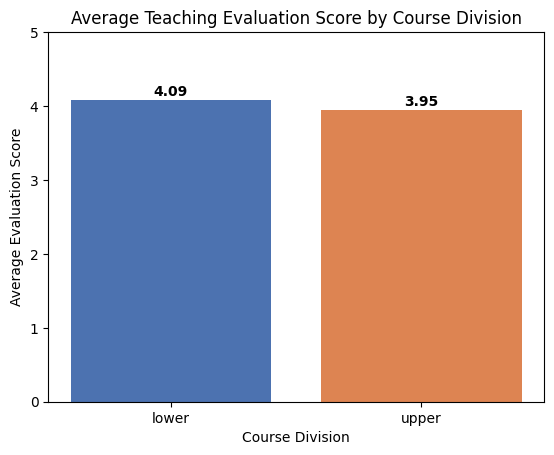


1. Average evaluation: lower division = 4.09, upper division = 3.95, a gap of 0.13.
2. Instructors teaching lower-division courses do receive slightly higher average ratings.
3. The gap is small compared with the spread of ratings (std is about 0.55), so the bars alone cannot prove it is real. A t-test would be needed.
4. The y-axis starts at 0, so the bars are not exaggerated. Cutting the axis would make a small gap look big.



In [7]:
division_eval = df.groupby('division')['eval'].mean()

plt.bar(division_eval.index, division_eval.values, color=['#4C72B0', '#DD8452'])
for i, v in enumerate(division_eval.values):
    plt.text(i, v + 0.05, f"{v:.2f}", ha='center', fontweight='bold')   # value labels
plt.xlabel("Course Division")
plt.ylabel("Average Evaluation Score")
plt.title("Average Teaching Evaluation Score by Course Division")
plt.ylim(0, 5)
plt.show()

low, up = division_eval['lower'], division_eval['upper']
print(f"""
1. Average evaluation: lower division = {low:.2f}, upper division = {up:.2f}, a gap of {low - up:.2f}.
2. Instructors teaching lower-division courses do receive slightly higher average ratings.
3. The gap is small compared with the spread of ratings (std is about 0.55), so the bars alone cannot prove it is real. A t-test would be needed.
4. The y-axis starts at 0, so the bars are not exaggerated. Cutting the axis would make a small gap look big.
""")

 Question 3. Plot the relationship between age and teaching evaluation scores.

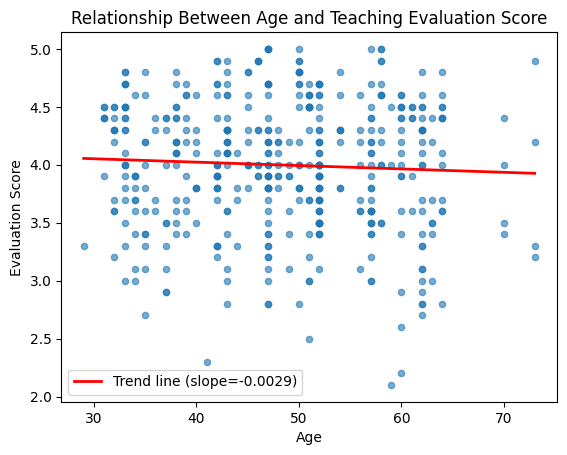


1. Correlation r = -0.0517, which is very close to 0, so there is almost no linear relationship between age and evaluation.
2. The trend line is nearly flat (slope = -0.0029): each extra year of age changes the predicted rating by only 0.0029.
3. r squared = 0.0027, so age explains only about 0.3% of the variation in ratings.
4. Good and poor ratings occur at every age, so age is not a useful predictor of teaching evaluation.



In [8]:
import numpy as np

df.plot(kind='scatter', x='age', y='eval', alpha=0.6)

m, c = np.polyfit(df['age'], df['eval'], 1)          # slope and intercept
xs = np.linspace(df['age'].min(), df['age'].max(), 100)
plt.plot(xs, m*xs + c, color='red', linewidth=2, label=f"Trend line (slope={m:.4f})")

plt.xlabel("Age")
plt.ylabel("Evaluation Score")
plt.title("Relationship Between Age and Teaching Evaluation Score")
plt.legend()
plt.show()

r = df['age'].corr(df['eval'])
print(f"""
1. Correlation r = {r:.4f}, which is very close to 0, so there is almost no linear relationship between age and evaluation.
2. The trend line is nearly flat (slope = {m:.4f}): each extra year of age changes the predicted rating by only {abs(m):.4f}.
3. r squared = {r**2:.4f}, so age explains only about {r**2*100:.1f}% of the variation in ratings.
4. Good and poor ratings occur at every age, so age is not a useful predictor of teaching evaluation.
""")

Question 4. Using gender-differentiated scatter plots, plot the relationship between age and teaching evaluation scores.

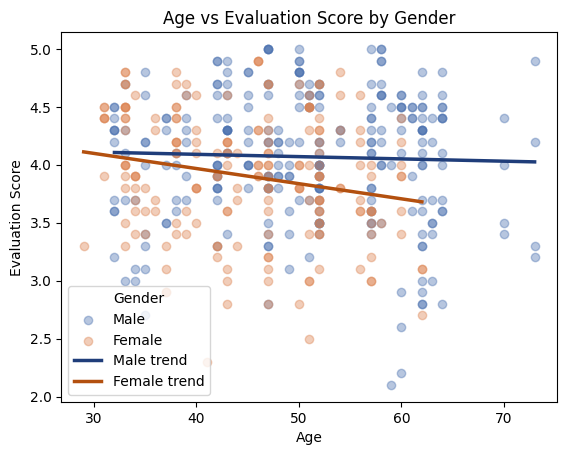

            mean       std  count
gender                           
female  3.901026  0.538803    195
male    4.069030  0.556652    268

1. Male instructors average 4.07 and female instructors 3.90, so men score about 0.17 higher on average.
2. The spread is similar (std 0.56 vs 0.54), so the gap is a shift in the average and not in variability.
3. Trend slopes: male = -0.0020, female = -0.0131. Both are close to flat, so age still has little effect within each gender.
4. The two groups overlap heavily, and the gap is small compared with the spread (this matches the significant but small effect, R squared = 0.022, from Practical 7).



In [9]:
def add_trend(sub, color, label, ls='-'):
    m, c = np.polyfit(sub['age'], sub['eval'], 1)
    xs = np.linspace(sub['age'].min(), sub['age'].max(), 100)
    plt.plot(xs, m*xs + c, color=color, linestyle=ls, linewidth=2.5, label=f"{label} trend")
    return m

males = df[df['gender'] == 'male']
females = df[df['gender'] == 'female']

plt.scatter(males['age'], males['eval'], color='#4C72B0', alpha=0.4, label='Male')
plt.scatter(females['age'], females['eval'], color='#DD8452', alpha=0.4, label='Female')
m_male = add_trend(males, '#1f3d7a', 'Male')
m_female = add_trend(females, '#b3500f', 'Female')

plt.xlabel("Age")
plt.ylabel("Evaluation Score")
plt.title("Age vs Evaluation Score by Gender")
plt.legend(title="Gender")
plt.show()

gender_stats = df.groupby('gender')['eval'].agg(['mean', 'std', 'count'])
print(gender_stats)

print(f"""
1. Male instructors average {gender_stats.loc['male','mean']:.2f} and female instructors {gender_stats.loc['female','mean']:.2f}, so men score about {gender_stats.loc['male','mean'] - gender_stats.loc['female','mean']:.2f} higher on average.
2. The spread is similar (std {gender_stats.loc['male','std']:.2f} vs {gender_stats.loc['female','std']:.2f}), so the gap is a shift in the average and not in variability.
3. Trend slopes: male = {m_male:.4f}, female = {m_female:.4f}. Both are close to flat, so age still has little effect within each gender.
4. The two groups overlap heavily, and the gap is small compared with the spread (this matches the significant but small effect, R squared = 0.022, from Practical 7).
""")

Question 5. Create a scatterplot of age and evaluation scores, differentiated by gender and tenure.

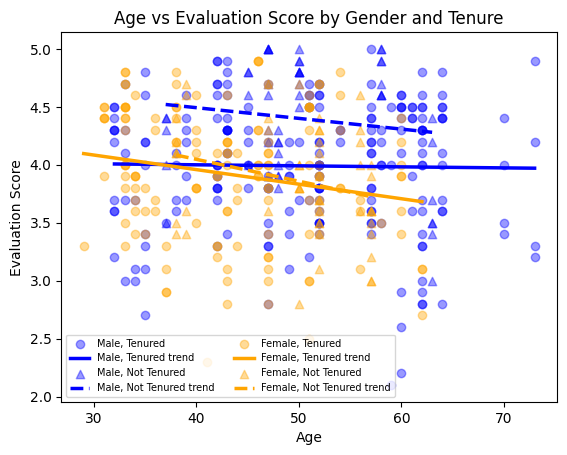

                   mean  count
gender tenure                 
female no      3.860000     50
       yes     3.915172    145
male   no      4.396154     52
       yes     3.990278    216

1. Mean evaluations: male untenured = 4.40, male tenured = 3.99, female untenured = 3.86, female tenured = 3.92.
2. Tenure matters for men (untenured men score 0.41 higher), but barely for women (gap of only 0.06).
3. So the effect of tenure depends on gender. This is called an interaction effect.
4. Check the group sizes (count column). Small groups, like untenured men, can give unreliable means.



In [10]:
groups = {
    ('male', 'yes'):   ('blue',   'o', '-',  'Male, Tenured'),
    ('male', 'no'):    ('blue',   '^', '--', 'Male, Not Tenured'),
    ('female', 'yes'): ('orange', 'o', '-',  'Female, Tenured'),
    ('female', 'no'):  ('orange', '^', '--', 'Female, Not Tenured'),
}

for (g, t), (col, mk, ls, lab) in groups.items():
    sub = df[(df['gender'] == g) & (df['tenure'] == t)]
    plt.scatter(sub['age'], sub['eval'], color=col, marker=mk, alpha=0.4, label=lab)
    add_trend(sub, col, lab, ls)

plt.xlabel("Age")
plt.ylabel("Evaluation Score")
plt.title("Age vs Evaluation Score by Gender and Tenure")
plt.legend(fontsize=7, ncol=2)
plt.show()

ts = df.groupby(['gender', 'tenure'])['eval'].agg(['mean', 'count'])
print(ts)

print(f"""
1. Mean evaluations: male untenured = {ts.loc[('male','no'),'mean']:.2f}, male tenured = {ts.loc[('male','yes'),'mean']:.2f}, female untenured = {ts.loc[('female','no'),'mean']:.2f}, female tenured = {ts.loc[('female','yes'),'mean']:.2f}.
2. Tenure matters for men (untenured men score {ts.loc[('male','no'),'mean'] - ts.loc[('male','yes'),'mean']:.2f} higher), but barely for women (gap of only {abs(ts.loc[('female','yes'),'mean'] - ts.loc[('female','no'),'mean']):.2f}).
3. So the effect of tenure depends on gender. This is called an interaction effect.
4. Check the group sizes (count column). Small groups, like untenured men, can give unreliable means.
""")